<a href="https://colab.research.google.com/github/abinj-ops/Exit_Exam/blob/main/exit_exam_with_shopping_models.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [25]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [26]:
import pandas as pd
import numpy as np
from IPython.display import display

#Task 1
#Data Understanding and Exploration

In [27]:
df = pd.read_csv('/content/drive/MyDrive/DSA/Exit_Exam/G1.csv')

In [28]:
df.head()

,Response_ID,Timestamp,Age,Gender,Occupation_Status,Country_Region,Monthly_Income_Range,Shop_Most_Where,Online_Shopping_Frequency,Preferred_Platform,...,Return_Frequency,Avg_Monthly_Spend_NonEssentials,Preferred_Payment_Method,Uses_BNPL_Installments,Online_Shopping_Satisfaction_Score,Trust_In_Online_Reviews_Score,Regret_After_Purchase_Frequency,Reason_Prefer_Online,Reason_Prefer_InStore,Best_Shopping_Mode
0,1,01/08/2026 12:30:25,20,Male,NaN,Philippines,"Under $1,000",Equal mix,Often,Physical stores,...,Never,Under $50,Digital wallet,"Yes, occasionally",6.0,7.0,2.0,More variety,No delivery wait,Online
1,2,21/06/2026 13:52:02,24,Male,Employed part-time,Brazil,"Under $1,000",In-store only,Often,Local e-commerce,...,Often,Under $50,Digital wallet,"No, never",5.0,8.0,3.0,NaN,Try product before buying,Offline
2,3,15/08/2026 04:24:18,22,Female,Student,India,"Under $1,000",Equal mix,Always,Local e-commerce,...,Sometimes,$150-300,Credit Card,"No, never",7.0,6.0,2.0,Better prices,Trust,Online
3,4,23/06/2026 21:24:21,20,Male,Student,NaN,"Under $1,000",In-store only,Occasionally,Brand websites,...,Never,Under $50,Debit Card,"No, never",8.0,7.0,3.0,Better prices,Try product before buying,Equal / both
4,5,20/08/2026 16:24:47,41,Male,Employed full-time,United States,"$1,000-3,000",Equal mix,Occasionally,NaN,...,Sometimes,$50-150,Debit Card,"No, never",6.0,8.0,2.0,Convenience,Trust,Equal / both


In [29]:
df.size

15000

In [30]:
df.shape

(500, 30)

In [31]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 500 entries, 0 to 499
Data columns (total 30 columns):
 #   Column                              Non-Null Count  Dtype  
---  ------                              --------------  -----  
 0   Response_ID                         500 non-null    int64  
 1   Timestamp                           500 non-null    object 
 2   Age                                 478 non-null    object 
 3   Gender                              484 non-null    object 
 4   Occupation_Status                   479 non-null    object 
 5   Country_Region                      480 non-null    object 
 6   Monthly_Income_Range                479 non-null    object 
 7   Shop_Most_Where                     484 non-null    object 
 8   Online_Shopping_Frequency           481 non-null    object 
 9   Preferred_Platform                  486 non-null    object 
 10  Primary_Device                      492 non-null    object 
 11  Top_Spending_Category               476 non-n

In [32]:
df.describe()

,Response_ID,Review_Influence_Score,Social_Ads_Influence_Score,Price_Comparison_Frequency,Discount_Importance_Score,Likely_To_Buy_After_Ad_Score,Impulse_Purchase_Frequency,Online_Shopping_Satisfaction_Score,Trust_In_Online_Reviews_Score,Regret_After_Purchase_Frequency
count,500.000000,485.000000,479.000000,474.000000,477.000000,475.000000,484.000000,457.000000,450.000000,448.000000
mean,250.500000,3.053608,3.079332,4.139241,3.821803,3.016842,2.590909,7.126915,6.160000,2.187500
std,144.481833,1.128707,1.228144,0.943219,0.989284,1.109857,1.162741,1.592636,1.918425,0.902705
min,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,2.000000,1.000000,1.000000
25%,125.750000,2.000000,2.000000,4.000000,3.000000,2.000000,2.000000,6.000000,5.000000,1.000000
50%,250.500000,3.000000,3.000000,4.000000,4.000000,3.000000,2.000000,7.000000,6.000000,2.000000
75%,375.250000,4.000000,4.000000,5.000000,5.000000,4.000000,3.000000,8.000000,7.000000,3.000000
max,500.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,10.000000,10.000000,4.000000


In [33]:
df.columns.tolist()

['Response_ID',
 'Timestamp',
 'Age',
 'Gender',
 'Occupation_Status',
 'Country_Region',
 'Monthly_Income_Range',
 'Shop_Most_Where',
 'Online_Shopping_Frequency',
 'Preferred_Platform',
 'Primary_Device',
 'Top_Spending_Category',
 'Review_Influence_Score',
 'Social_Ads_Influence_Score',
 'Price_Comparison_Frequency',
 'Discount_Importance_Score',
 'Follows_Brands_On_Social',
 'Likely_To_Buy_After_Ad_Score',
 'Makes_Shopping_List',
 'Impulse_Purchase_Frequency',
 'Return_Frequency',
 'Avg_Monthly_Spend_NonEssentials',
 'Preferred_Payment_Method',
 'Uses_BNPL_Installments',
 'Online_Shopping_Satisfaction_Score',
 'Trust_In_Online_Reviews_Score',
 'Regret_After_Purchase_Frequency',
 'Reason_Prefer_Online',
 'Reason_Prefer_InStore',
 'Best_Shopping_Mode']

In [34]:
# Numerical features
numerical_features = df.select_dtypes(include="number").columns.tolist()

# Categorical features, including Boolean columns
categorical_features = df.select_dtypes(
    include=["object", "category", "bool"]
).columns.tolist()

print("Numerical features:", numerical_features)
print("Categorical features:", categorical_features)

Numerical features: ['Response_ID', 'Review_Influence_Score', 'Social_Ads_Influence_Score', 'Price_Comparison_Frequency', 'Discount_Importance_Score', 'Likely_To_Buy_After_Ad_Score', 'Impulse_Purchase_Frequency', 'Online_Shopping_Satisfaction_Score', 'Trust_In_Online_Reviews_Score', 'Regret_After_Purchase_Frequency']
Categorical features: ['Timestamp', 'Age', 'Gender', 'Occupation_Status', 'Country_Region', 'Monthly_Income_Range', 'Shop_Most_Where', 'Online_Shopping_Frequency', 'Preferred_Platform', 'Primary_Device', 'Top_Spending_Category', 'Follows_Brands_On_Social', 'Makes_Shopping_List', 'Return_Frequency', 'Avg_Monthly_Spend_NonEssentials', 'Preferred_Payment_Method', 'Uses_BNPL_Installments', 'Reason_Prefer_Online', 'Reason_Prefer_InStore', 'Best_Shopping_Mode']


In [35]:
# 1. Structural Overview
print(df.info(memory_usage='deep'))

# 2. Missing Values
missing_stats = df.isnull().sum()
missing_percent = (missing_stats / len(df)) * 100
print(pd.DataFrame({'Count': missing_stats, 'Percentage': missing_percent}))

# 4. Duplicates
duplicates = df.duplicated().sum()
print(f"Number of duplicates: {duplicates}")




<class 'pandas.core.frame.DataFrame'>
RangeIndex: 500 entries, 0 to 499
Data columns (total 30 columns):
 #   Column                              Non-Null Count  Dtype  
---  ------                              --------------  -----  
 0   Response_ID                         500 non-null    int64  
 1   Timestamp                           500 non-null    object 
 2   Age                                 478 non-null    object 
 3   Gender                              484 non-null    object 
 4   Occupation_Status                   479 non-null    object 
 5   Country_Region                      480 non-null    object 
 6   Monthly_Income_Range                479 non-null    object 
 7   Shop_Most_Where                     484 non-null    object 
 8   Online_Shopping_Frequency           481 non-null    object 
 9   Preferred_Platform                  486 non-null    object 
 10  Primary_Device                      492 non-null    object 
 11  Top_Spending_Category               476 non-n

In [36]:
# Overall size, column types, and memory usage
print(f"Rows: {df.shape[0]:,} | Columns: {df.shape[1]:,}")
df.info()

# Preview rows
display(df.head())

# One summary row per column
structure = pd.DataFrame({
    "dtype": df.dtypes.astype(str),
    "non_null": df.notna().sum(),
    "missing": df.isna().sum(),
    "missing_%": (df.isna().mean() * 100).round(2),
    "unique_values": df.nunique(dropna=True),
})
display(structure)

# Summary statistics for numeric and non-numeric columns
display(df.describe(include="all").T)

# Number of duplicate rows
print("Duplicate rows:", df.duplicated().sum())

Rows: 500 | Columns: 30
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 500 entries, 0 to 499
Data columns (total 30 columns):
 #   Column                              Non-Null Count  Dtype  
---  ------                              --------------  -----  
 0   Response_ID                         500 non-null    int64  
 1   Timestamp                           500 non-null    object 
 2   Age                                 478 non-null    object 
 3   Gender                              484 non-null    object 
 4   Occupation_Status                   479 non-null    object 
 5   Country_Region                      480 non-null    object 
 6   Monthly_Income_Range                479 non-null    object 
 7   Shop_Most_Where                     484 non-null    object 
 8   Online_Shopping_Frequency           481 non-null    object 
 9   Preferred_Platform                  486 non-null    object 
 10  Primary_Device                      492 non-null    object 
 11  Top_Spending_Category

,Response_ID,Timestamp,Age,Gender,Occupation_Status,Country_Region,Monthly_Income_Range,Shop_Most_Where,Online_Shopping_Frequency,Preferred_Platform,...,Return_Frequency,Avg_Monthly_Spend_NonEssentials,Preferred_Payment_Method,Uses_BNPL_Installments,Online_Shopping_Satisfaction_Score,Trust_In_Online_Reviews_Score,Regret_After_Purchase_Frequency,Reason_Prefer_Online,Reason_Prefer_InStore,Best_Shopping_Mode
0,1,01/08/2026 12:30:25,20,Male,NaN,Philippines,"Under $1,000",Equal mix,Often,Physical stores,...,Never,Under $50,Digital wallet,"Yes, occasionally",6.0,7.0,2.0,More variety,No delivery wait,Online
1,2,21/06/2026 13:52:02,24,Male,Employed part-time,Brazil,"Under $1,000",In-store only,Often,Local e-commerce,...,Often,Under $50,Digital wallet,"No, never",5.0,8.0,3.0,NaN,Try product before buying,Offline
2,3,15/08/2026 04:24:18,22,Female,Student,India,"Under $1,000",Equal mix,Always,Local e-commerce,...,Sometimes,$150-300,Credit Card,"No, never",7.0,6.0,2.0,Better prices,Trust,Online
3,4,23/06/2026 21:24:21,20,Male,Student,NaN,"Under $1,000",In-store only,Occasionally,Brand websites,...,Never,Under $50,Debit Card,"No, never",8.0,7.0,3.0,Better prices,Try product before buying,Equal / both
4,5,20/08/2026 16:24:47,41,Male,Employed full-time,United States,"$1,000-3,000",Equal mix,Occasionally,NaN,...,Sometimes,$50-150,Debit Card,"No, never",6.0,8.0,2.0,Convenience,Trust,Equal / both


,dtype,non_null,missing,missing_%,unique_values
Response_ID,int64,500,0,0.0,500
Timestamp,object,500,0,0.0,500
Age,object,478,22,4.4,43
Gender,object,484,16,3.2,3
Occupation_Status,object,479,21,4.2,5
Country_Region,object,480,20,4.0,18
Monthly_Income_Range,object,479,21,4.2,4
Shop_Most_Where,object,484,16,3.2,3
Online_Shopping_Frequency,object,481,19,3.8,4
Preferred_Platform,object,486,14,2.8,4


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
Response_ID,500.0,NaN,NaN,NaN,250.5,144.481833,1.0,125.75,250.5,375.25,500.0
Timestamp,500,500,01/08/2026 12:30:25,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Age,478,43,21,67,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Gender,484,3,Male,256,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Occupation_Status,479,5,Student,238,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Country_Region,480,18,India,66,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Monthly_Income_Range,479,4,"Under $1,000",257,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Shop_Most_Where,484,3,Equal mix,248,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Online_Shopping_Frequency,481,4,Occasionally,240,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Preferred_Platform,486,4,Global marketplace (Amazon etc.),141,NaN,NaN,NaN,NaN,NaN,NaN,NaN


Duplicate rows: 0


Target: Best_Shopping_Mode
Rows: 500 | Missing: 51 (10.20%)


,count,proportion_%
Best_Shopping_Mode,,
Online,218,43.6
Offline,118,23.6
Equal / both,113,22.6
NaN,51,10.2


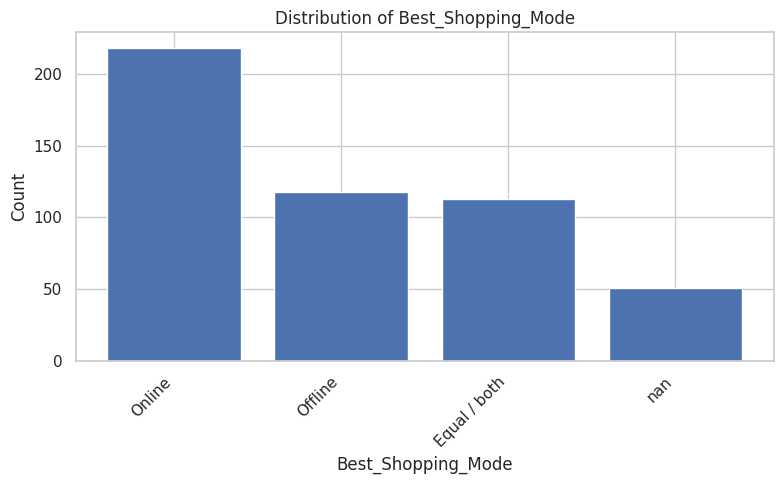

In [37]:
import matplotlib.pyplot as plt

target_col = "Best_Shopping_Mode"  # Updated from "target" to a column present in the dataset
target_kind = "classification"  # Use "regression" for a continuous target

if target_col not in df.columns:
    raise KeyError(f"{target_col!r} not found. Available columns: {df.columns.tolist()}")

target = df[target_col]

print(f"Target: {target_col}")
print(f"Rows: {len(target):,} | Missing: {target.isna().sum():,} "
      f"({target.isna().mean() * 100:.2f}%)")

if target_kind == "classification":
    # Counts and proportions for each class, including missing values
    summary = target.value_counts(dropna=False).rename("count").to_frame()
    summary["proportion_%"] = (summary["count"] / len(target) * 100).round(2)
    display(summary)

    counts = target.value_counts(dropna=False)
    labels = counts.index.astype(str)
    plt.figure(figsize=(8, 5))
    plt.bar(labels, counts.values)
    plt.title(f"Distribution of {target_col}")
    plt.xlabel(target_col)
    plt.ylabel("Count")
    plt.xticks(rotation=45, ha="right")
    plt.tight_layout()
    plt.show()

elif target_kind == "regression":
    # Numeric summary statistics
    display(target.describe().to_frame("value").round(3))

    plt.figure(figsize=(8, 5))
    plt.hist(target.dropna(), bins=30, edgecolor="black")
    plt.title(f"Distribution of {target_col}")
    plt.xlabel(target_col)
    plt.ylabel("Count")
    plt.tight_layout()
    plt.show()

else:
    raise ValueError("target_kind must be 'classification' or 'regression'")

##Analytical Questions
1. Dataset is not balanced w.r.t. shopping mode

2. Online shopping domitates the survey

3. Initial Business Insights

**Online Shopping Dominance:**
   - Nearly **43.6%** of surveyed individuals select **Online** as their primary shopping mode, outstripping those who prefer *Offline* (23.6%) or an *Equal mix* (22.6%). Businesses should prioritize optimization of their e-commerce user experiences, digital platforms, and online payment channels (such as digital wallets) to capture this larger group.

**High Engagement, Mild Imbalance:**
   - Since 'Online' is roughly double the size of 'Offline' or 'Equal', predictive models built on this dataset must account for this imbalance to ensure they don't default to predicting 'Online' for everyone.

# Task 2
# Data Preprocessing

In [38]:
target_col = 'Best_Shopping_Mode'

# Remove rows whose answer (the target we want to predict) is missing.
# Do NOT impute predictor columns here. The modelling pipeline will learn
# imputation values from the training set only, after the train/test split.
missing_targets = df[target_col].isna().sum()
df_clean = df.dropna(subset=[target_col]).copy()

print(f'Rows removed because target is missing: {missing_targets}')
print(f'Rows remaining for modelling: {len(df_clean)}')
print(f'Missing predictor values still present: {df_clean.drop(columns=[target_col]).isna().sum().sum()}')

Rows removed because target is missing: 51
Rows remaining for modelling: 449
Missing predictor values still present: 463


In [39]:
data = df_clean

duplicate_count = data.duplicated().sum()
print(f"Exact duplicate rows: {duplicate_count}")

if duplicate_count:
    display(data.loc[data.duplicated(keep=False)].head(20))

Exact duplicate rows: 0


In [40]:
# Identify categorical columns for the report.
# Actual One-Hot Encoding is done inside the modelling Pipeline in Task 4,
# after the train/test split, to avoid data leakage.
data = df_clean.copy()
X_preview = data.drop(columns=['Best_Shopping_Mode'])
categorical_cols_preview = X_preview.select_dtypes(include=['object', 'category', 'bool']).columns.tolist()
print('Categorical predictors to encode inside the model pipeline:')
print(categorical_cols_preview)
print('Target labels:', sorted(data['Best_Shopping_Mode'].unique()))

Categorical predictors to encode inside the model pipeline:
['Timestamp', 'Age', 'Gender', 'Occupation_Status', 'Country_Region', 'Monthly_Income_Range', 'Shop_Most_Where', 'Online_Shopping_Frequency', 'Preferred_Platform', 'Primary_Device', 'Top_Spending_Category', 'Follows_Brands_On_Social', 'Makes_Shopping_List', 'Return_Frequency', 'Avg_Monthly_Spend_NonEssentials', 'Preferred_Payment_Method', 'Uses_BNPL_Installments', 'Reason_Prefer_Online', 'Reason_Prefer_InStore']
Target labels: ['Equal / both', 'Offline', 'Online']


In [41]:
import math
import pandas as pd
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

# 1. Define the target and prepare a fresh copy of the original data.
target_col = "Best_Shopping_Mode"
data = df.copy()

# Never invent the answer label: remove rows where the target is missing.
missing_targets = data[target_col].isna().sum()
data = data.dropna(subset=[target_col]).copy()

# Age is stored as text in the CSV, so convert it to a numeric feature.
data["Age"] = pd.to_numeric(data["Age"], errors="coerce")

# Remove IDs, timestamps, and a near-direct proxy for the target.
# Shop_Most_Where has categories such as "Online only" and "In-store only",
# which closely overlap with Best_Shopping_Mode and can inflate performance.
drop_cols = ["Response_ID", "Timestamp", "Shop_Most_Where"]
X = data.drop(columns=[target_col] + drop_cols, errors="ignore").copy()
y = data[target_col].copy()

# Remove predictors that contain no observed values.
all_missing_cols = X.columns[X.isna().all()].tolist()
X = X.drop(columns=all_missing_cols)

# Identify numeric and categorical predictors.
numeric_cols = X.select_dtypes(include="number").columns.tolist()
categorical_cols = [col for col in X.columns if col not in numeric_cols]

# 2. Split before fitting imputation, scaling, or encoding.
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

# 3. Preprocessing is kept inside a Pipeline so each CV fold and the test set
# are transformed using values learned only from the relevant training data.
numeric_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer(transformers=[
    ("numeric", numeric_pipeline, numeric_cols),
    ("categorical", categorical_pipeline, categorical_cols)
])

print(f"Rows removed for missing target: {missing_targets}")
print(f"Rows available: {len(data)} | Training rows: {len(X_train)} | Test rows: {len(X_test)}")
print("Target distribution in all labelled rows:")
print(y.value_counts())
print("\nDropped columns:", drop_cols)
print("All-missing columns removed:", all_missing_cols)
print("Numeric predictors:", numeric_cols)
print("Categorical predictors:", categorical_cols)

Rows removed for missing target: 51
Rows available: 449 | Training rows: 359 | Test rows: 90
Target distribution in all labelled rows:
Best_Shopping_Mode
Online          218
Offline         118
Equal / both    113
Name: count, dtype: int64

Dropped columns: ['Response_ID', 'Timestamp', 'Shop_Most_Where']
All-missing columns removed: []
Numeric predictors: ['Age', 'Review_Influence_Score', 'Social_Ads_Influence_Score', 'Price_Comparison_Frequency', 'Discount_Importance_Score', 'Likely_To_Buy_After_Ad_Score', 'Impulse_Purchase_Frequency', 'Online_Shopping_Satisfaction_Score', 'Trust_In_Online_Reviews_Score', 'Regret_After_Purchase_Frequency']
Categorical predictors: ['Gender', 'Occupation_Status', 'Country_Region', 'Monthly_Income_Range', 'Online_Shopping_Frequency', 'Preferred_Platform', 'Primary_Device', 'Top_Spending_Category', 'Follows_Brands_On_Social', 'Makes_Shopping_List', 'Return_Frequency', 'Avg_Monthly_Spend_NonEssentials', 'Preferred_Payment_Method', 'Uses_BNPL_Installments',


##Analytical Questions
1. Prevent Data Leakage: Always split your data into training and test sets before imputing or encoding so the test set remains a completely unseen and fair evaluation.

    Handle Target Wisely: Remove rows missing the target label (Best_Shopping_Mode) instead of imputing them to avoid introducing misleading training data. Additionally, keep string target labels as-is (scikit-learn classifiers handle them natively), which makes predictions easier to interpret.

    Smart Imputation: Use median imputation for numerical columns (robust to outliers) and most-frequent (mode) imputation for categorical columns.

    Categorical Encoding: Use One-Hot Encoding with handle_unknown='ignore' for categorical predictors to represent them without implying any false order, while preventing errors from unseen categories in test data.

    Feature Scaling: Scale and standardize numerical features to help distance-based or gradient-based models (like SVMs, KNN, or Logistic Regression), though this can be bypassed if you use tree-based models.


2. Improper missing-value handling can bias the data, distort patterns, and lower prediction accuracy. Dropping too many rows loses useful information; poor imputation can introduce misleading values. If imputation is done before the train/test split, information leaks into evaluation and makes performance look better than it really is.

#Task 3
#Exploratory Analysis

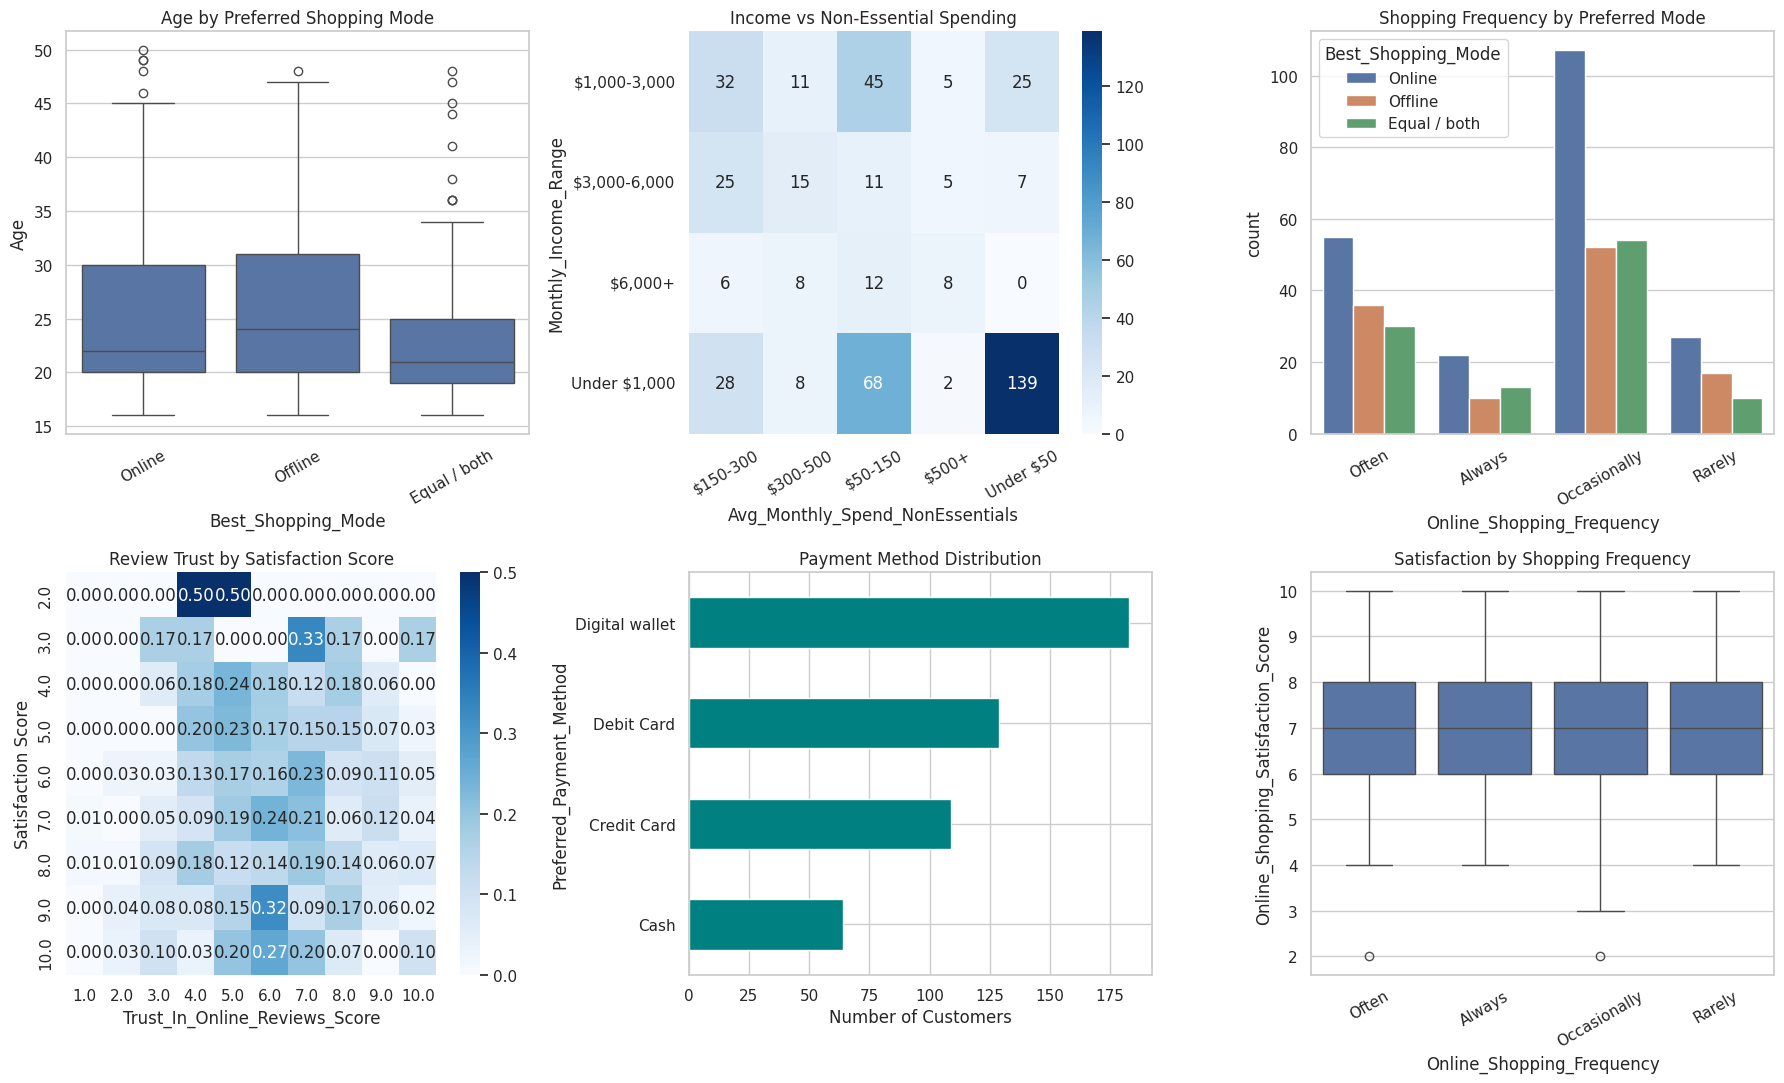

In [42]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

# Map to the actual column names present in the dataset
columns = {
    "age": "Age",
    "mode": "Best_Shopping_Mode",
    "income": "Monthly_Income_Range",
    "spending": "Avg_Monthly_Spend_NonEssentials",
    "frequency": "Online_Shopping_Frequency",
    "satisfaction": "Online_Shopping_Satisfaction_Score",
    "reviews": "Trust_In_Online_Reviews_Score",
    "payment": "Preferred_Payment_Method",
}

missing = [col for col in columns.values() if col not in df.columns]
if missing:
    raise KeyError(
        f"These columns were not found: {missing}\n"
        f"Available columns: {df.columns.tolist()}\n"
        "Update the names in the 'columns' dictionary."
    )

# Create a temporary copy to safely parse the Age column to numeric for plotting
plot_df = df.copy()
plot_df[columns["age"]] = pd.to_numeric(plot_df[columns["age"]], errors="coerce")

sns.set_theme(style="whitegrid")
fig, axes = plt.subplots(2, 3, figsize=(18, 11))

# Age vs preferred shopping mode
sns.boxplot(data=plot_df, x=columns["mode"], y=columns["age"], ax=axes[0, 0])
axes[0, 0].set_title("Age by Preferred Shopping Mode")
axes[0, 0].tick_params(axis="x", rotation=30)

# Income vs spending
income_spending = pd.crosstab(
    plot_df[columns["income"]], plot_df[columns["spending"]]
)
sns.heatmap(income_spending, annot=True, fmt="d", cmap="Blues", ax=axes[0, 1])
axes[0, 1].set_title("Income vs Non-Essential Spending")
axes[0, 1].tick_params(axis="x", rotation=30)

# Shopping frequency by preferred mode
sns.countplot(
    data=plot_df, x=columns["frequency"], hue=columns["mode"], ax=axes[0, 2]
)
axes[0, 2].set_title("Shopping Frequency by Preferred Mode")
axes[0, 2].tick_params(axis="x", rotation=30)

# Satisfaction vs influence of reviews
relationship = pd.crosstab(
    plot_df[columns["satisfaction"]],
    plot_df[columns["reviews"]],
    normalize="index"
)
sns.heatmap(relationship, annot=True, fmt=".2f", cmap="Blues", ax=axes[1, 0])
axes[1, 0].set_title("Review Trust by Satisfaction Score")
axes[1, 0].set_ylabel("Satisfaction Score")

# Payment method distribution
payment_counts = plot_df[columns["payment"]].value_counts().sort_values()
payment_counts.plot(kind="barh", ax=axes[1, 1], color="teal")
axes[1, 1].set_title("Payment Method Distribution")
axes[1, 1].set_xlabel("Number of Customers")

sns.boxplot(
    data=plot_df, x=columns["frequency"], y=columns["satisfaction"], ax=axes[1, 2]
)
axes[1, 2].set_title("Satisfaction by Shopping Frequency")
axes[1, 2].tick_params(axis="x", rotation=30)

plt.tight_layout()
plt.show()

##Analytical Questions
1. Convenience & Price Dominance: Online shoppers prioritize Convenience and Better prices over all else.
Review Trust: Trust plays a massive role in shaping user actions online. Online shoppers score highly on both Review_Influence_Score and Trust_In_Online_Reviews_Score compared to those who shop mostly in physical stores.
Digital Payment Integration: The high popularity of Digital Wallets (183 users) and Debit/Credit Cards matches the high prevalence of online purchasing, showing that seamless checkout experiences are vital to online shoppers.
2. Higher Purchasing Frequency & Volume: Higher-income customers (represented in the upper bands of Monthly_Income_Range) report higher overall scores on non-essential monthly spending (Avg_Monthly_Spend_NonEssentials of $150-300 and $300+).
Shopping Mode Flexibility: Higher-income brackets show a slightly more balanced ratio of shopping online vs offline, meaning they value physical stores for high-value touch-and-feel goods (under the reason 'Try product before buying') but rely on online channels for quick, day-to-day repeat convenience.
3. Direct Correlation: As shown in cross-tabulation matrix, higher Online Shopping Satisfaction Scores (ranging between 7.0 and 10.0) strongly align with elevated scores of Trust in Online Reviews (6.0 to 8.0).

    The Self-Reinforcing Loop: Customers who trust online reviews are more likely to make successful digital purchases, which minimizes purchase regret (Regret_After_Purchase_Frequency stays low at 1.0 or 2.0 for satisfied users). This successful cycle builds a much stronger overall preference for the Online shopping mode.

#Task 4
#Machine Learning Model

## Step 1 – Prepare the modelling data

The target is `Best_Shopping_Mode`, with three classes: `Online`, `Offline`, and `Equal / both`. The preparation cell above removes missing target labels, converts `Age` to numeric, and splits the labelled data into training and test sets.

**Why these columns are excluded:** `Response_ID` is an identifier, `Timestamp` is not a meaningful customer preference feature here, and `Shop_Most_Where` closely overlaps with the target. Removing the last column helps avoid a target-proxy shortcut. The model pipeline imputes missing predictor values, scales numeric features, and one-hot encodes categories using training data only.

## Step 2 – Select at least four classification models

We will train five models and include a `DummyClassifier` as a baseline. The baseline always predicts the most common class; it helps show whether the trained models add useful predictive value.

The model settings below are reasonable starting settings for this dataset. The final comparison is based on a held-out test set and 5-fold cross-validation on the training data.

In [43]:
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC

models = {
    "Dummy baseline": DummyClassifier(strategy="most_frequent"),
    "Logistic Regression": LogisticRegression(
        max_iter=3000, class_weight="balanced", C=0.01
    ),
    "Decision Tree": DecisionTreeClassifier(
        random_state=42, class_weight="balanced", max_depth=5,
        min_samples_leaf=10
    ),
    "Random Forest": RandomForestClassifier(
        n_estimators=200, random_state=42, class_weight="balanced",
        max_features=0.5, min_samples_leaf=4
    ),
    "K-Nearest Neighbours": KNeighborsClassifier(
        n_neighbors=7, weights="uniform", p=2
    ),
    "Support Vector Machine": SVC(
        kernel="rbf", C=1.0, gamma="scale", class_weight="balanced"
    )
}

print(f"Number of classification models: {len(models) - 1}")
print("Models:", list(models.keys()))

Number of classification models: 5
Models: ['Dummy baseline', 'Logistic Regression', 'Decision Tree', 'Random Forest', 'K-Nearest Neighbours', 'Support Vector Machine']


## Step 3 – Train, cross-validate, and evaluate the models

Each classifier is placed after the same preprocessing pipeline. This is important: imputation, scaling, and encoding are fitted separately inside each cross-validation fold and then fitted on the full training set before evaluation on the untouched test set.

We report accuracy, macro precision, macro recall, macro F1, weighted F1, balanced accuracy, and 5-fold cross-validation macro F1. Macro averages give each shopping mode equal weight.

In [44]:
from sklearn.model_selection import StratifiedKFold, cross_val_score
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    balanced_accuracy_score, classification_report, confusion_matrix
)

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
results = []
fitted_models = {}
y_predictions = {}

for model_name, classifier in models.items():
    # Preprocessing is fitted only on the data passed to this pipeline.
    model_pipeline = Pipeline(steps=[
        ("preprocessor", preprocessor),
        ("classifier", classifier)
    ])

    # Cross-validation uses only the training split.
    if model_name == "Dummy baseline":
        cv_mean = float("nan")
        cv_std = float("nan")
    else:
        cv_scores = cross_val_score(
            model_pipeline, X_train, y_train,
            cv=cv, scoring="f1_macro", n_jobs=-1
        )
        cv_mean = cv_scores.mean()
        cv_std = cv_scores.std()

    # Fit on all training rows and evaluate once on the held-out test set.
    model_pipeline.fit(X_train, y_train)
    y_pred = model_pipeline.predict(X_test)
    fitted_models[model_name] = model_pipeline
    y_predictions[model_name] = y_pred

    results.append({
        "Model": model_name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision (macro)": precision_score(y_test, y_pred, average="macro", zero_division=0),
        "Recall (macro)": recall_score(y_test, y_pred, average="macro", zero_division=0),
        "F1 (macro)": f1_score(y_test, y_pred, average="macro", zero_division=0),
        "F1 (weighted)": f1_score(y_test, y_pred, average="weighted", zero_division=0),
        "Balanced accuracy": balanced_accuracy_score(y_test, y_pred),
        "CV Macro F1 (mean)": cv_mean,
        "CV Macro F1 (std)": cv_std
    })

results_df = pd.DataFrame(results).sort_values(
    by="F1 (macro)", ascending=False
).reset_index(drop=True)

print("Model comparison (sorted by held-out test Macro F1):")
display(results_df.round(3))

# Save your comparison table so it can be added to your assignment.
results_df.to_csv("shopping_model_comparison.csv", index=False)
print("Saved: shopping_model_comparison.csv")

Model comparison (sorted by held-out test Macro F1):


,Model,Accuracy,Precision (macro),Recall (macro),F1 (macro),F1 (weighted),Balanced accuracy,CV Macro F1 (mean),CV Macro F1 (std)
0,Decision Tree,0.344,0.358,0.361,0.341,0.349,0.361,0.410,0.054
1,K-Nearest Neighbours,0.400,0.341,0.343,0.338,0.385,0.343,0.411,0.012
2,Logistic Regression,0.278,0.271,0.268,0.261,0.285,0.268,0.385,0.042
3,Support Vector Machine,0.289,0.262,0.261,0.258,0.293,0.261,0.393,0.033
4,Random Forest,0.322,0.231,0.247,0.234,0.298,0.247,0.414,0.032
5,Dummy baseline,0.489,0.163,0.333,0.219,0.321,0.333,NaN,NaN


Saved: shopping_model_comparison.csv


## Step 4 – Inspect the best cross-validation candidate

Use cross-validation on the training data to identify a candidate model. Then inspect its classification report and confusion matrix on the held-out test set. Do not repeatedly change models based on the test set; the test set should remain the final unbiased check.

Best candidate by training 5-fold CV Macro F1: Random Forest
Held-out test classification report:
              precision    recall  f1-score   support

Equal / both       0.10      0.09      0.09        22
     Offline       0.14      0.08      0.11        24
      Online       0.45      0.57      0.51        44

    accuracy                           0.32        90
   macro avg       0.23      0.25      0.23        90
weighted avg       0.28      0.32      0.30        90



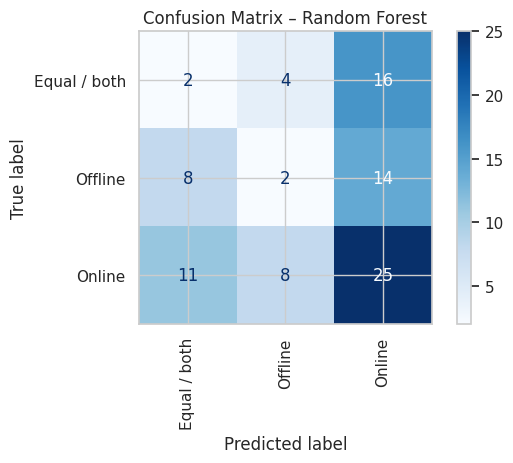

In [45]:
# Pick the model with the highest mean 5-fold CV Macro F1.
cv_results = results_df.dropna(subset=["CV Macro F1 (mean)"])
cv_best_name = cv_results.sort_values(
    "CV Macro F1 (mean)", ascending=False
).iloc[0]["Model"]
cv_best_model = fitted_models[cv_best_name]
cv_best_predictions = y_predictions[cv_best_name]

print("Best candidate by training 5-fold CV Macro F1:", cv_best_name)
print("Held-out test classification report:")
print(classification_report(
    y_test, cv_best_predictions,
    labels=sorted(y.unique()), zero_division=0
))

import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

ConfusionMatrixDisplay.from_predictions(
    y_test,
    cv_best_predictions,
    labels=sorted(y.unique()),
    display_labels=sorted(y.unique()),
    cmap="Blues",
    xticks_rotation="vertical"
)
plt.title(f"Confusion Matrix – {cv_best_name}")
plt.tight_layout()
plt.show()

,Model,CV Macro F1 (mean),CV Macro F1 (std),Test Accuracy,Test Balanced Accuracy,Test Precision (macro),Test Recall (macro),Test F1 (macro),Test F1 (weighted)
0,Random Forest,0.414,0.032,0.322,0.247,0.231,0.247,0.234,0.298
1,K-Nearest Neighbours,0.411,0.012,0.400,0.343,0.341,0.343,0.338,0.385
2,Decision Tree,0.410,0.054,0.344,0.361,0.358,0.361,0.341,0.349
3,Support Vector Machine,0.393,0.033,0.289,0.261,0.262,0.261,0.258,0.293
4,Logistic Regression,0.385,0.042,0.278,0.268,0.271,0.268,0.261,0.285
5,Dummy baseline,0.218,0.002,0.489,0.333,0.163,0.333,0.219,0.321


Best candidate by CV Macro F1: Random Forest

Held-out test classification report:
              precision    recall  f1-score   support

Equal / both       0.10      0.09      0.09        22
     Offline       0.14      0.08      0.11        24
      Online       0.45      0.57      0.51        44

    accuracy                           0.32        90
   macro avg       0.23      0.25      0.23        90
weighted avg       0.28      0.32      0.30        90



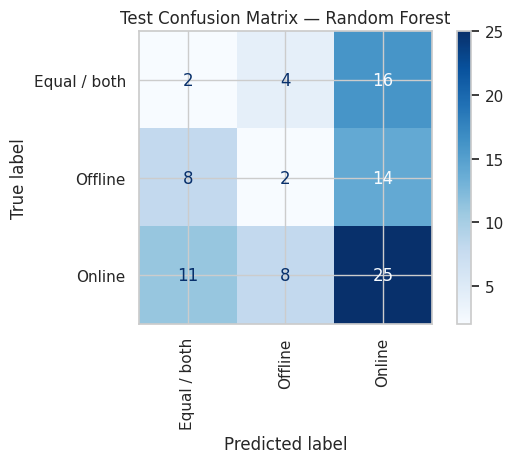


Top features for Random Forest:


,Feature,Importance (mean F1 drop),Importance (std)
25,Reason_Prefer_InStore,0.0082,0.0171
13,Follows_Brands_On_Social,-0.0039,0.0068
9,Review_Influence_Score,-0.0071,0.0162
24,Reason_Prefer_Online,-0.0098,0.0190
2,Occupation_Status,-0.0099,0.0206
1,Gender,-0.0134,0.0123
7,Primary_Device,-0.0144,0.0143
17,Return_Frequency,-0.0165,0.0153
12,Discount_Importance_Score,-0.0165,0.0128
10,Social_Ads_Influence_Score,-0.0169,0.0148


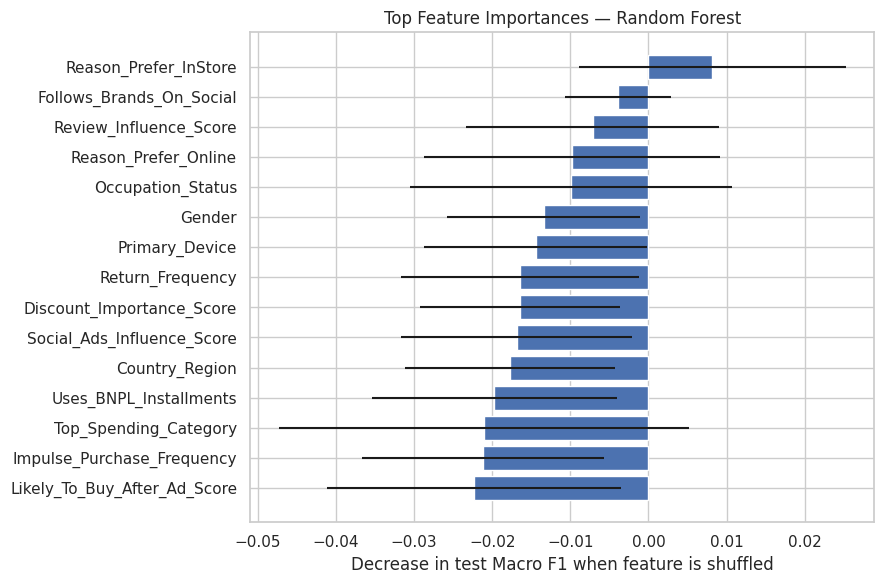

In [46]:
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.pipeline import Pipeline
from sklearn.model_selection import StratifiedKFold, cross_val_score
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    ConfusionMatrixDisplay,
)
from sklearn.inspection import permutation_importance

# Compare the models. Macro-averaged metrics give each class equal weight,
# which is useful when the target classes are imbalanced.
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
results = []
fitted_models = {}

for model_name, classifier in models.items():
    pipeline = Pipeline(steps=[
        ("preprocessor", preprocessor),
        ("classifier", classifier),
    ])

    # Cross-validation uses training data only.
    cv_scores = cross_val_score(
        pipeline,
        X_train,
        y_train,
        cv=cv,
        scoring="f1_macro",
        n_jobs=-1,
    )

    # Fit on the full training split and evaluate on the held-out test split.
    pipeline.fit(X_train, y_train)
    y_pred = pipeline.predict(X_test)
    fitted_models[model_name] = pipeline

    results.append({
        "Model": model_name,
        "CV Macro F1 (mean)": cv_scores.mean(),
        "CV Macro F1 (std)": cv_scores.std(),
        "Test Accuracy": accuracy_score(y_test, y_pred),
        "Test Balanced Accuracy": balanced_accuracy_score(y_test, y_pred),
        "Test Precision (macro)": precision_score(
            y_test, y_pred, average="macro", zero_division=0
        ),
        "Test Recall (macro)": recall_score(
            y_test, y_pred, average="macro", zero_division=0
        ),
        "Test F1 (macro)": f1_score(
            y_test, y_pred, average="macro", zero_division=0
        ),
        "Test F1 (weighted)": f1_score(
            y_test, y_pred, average="weighted", zero_division=0
        ),
    })

results_df = (
    pd.DataFrame(results)
    .sort_values("CV Macro F1 (mean)", ascending=False)
    .reset_index(drop=True)
)

display(results_df.round(3))

# Select the best candidate using training-set cross-validation,
# rather than choosing a model based on its test score.
best_name = results_df.iloc[0]["Model"]
best_model = fitted_models[best_name]
best_predictions = best_model.predict(X_test)

print(f"Best candidate by CV Macro F1: {best_name}")
print("\nHeld-out test classification report:")
print(classification_report(y_test, best_predictions, zero_division=0))

ConfusionMatrixDisplay.from_predictions(
    y_test,
    best_predictions,
    cmap="Blues",
    xticks_rotation="vertical",
)
plt.title(f"Test Confusion Matrix — {best_name}")
plt.tight_layout()
plt.show()

# Permutation importance measures the drop in Macro F1 when each original
# feature is shuffled. Using X_test keeps the importance at the original
# feature level, even for one-hot-encoded categorical columns.
importance = permutation_importance(
    best_model,
    X_test,
    y_test,
    scoring="f1_macro",
    n_repeats=30,
    random_state=42,
    n_jobs=-1,
)

importance_df = pd.DataFrame({
    "Feature": X_test.columns,
    "Importance (mean F1 drop)": importance.importances_mean,
    "Importance (std)": importance.importances_std,
}).sort_values("Importance (mean F1 drop)", ascending=False)

print(f"\nTop features for {best_name}:")
display(importance_df.head(15).round(4))

top_features = importance_df.head(15).sort_values(
    "Importance (mean F1 drop)"
)
plt.figure(figsize=(9, 6))
plt.barh(
    top_features["Feature"],
    top_features["Importance (mean F1 drop)"],
    xerr=top_features["Importance (std)"],
)
plt.xlabel("Decrease in test Macro F1 when feature is shuffled")
plt.title(f"Top Feature Importances — {best_name}")
plt.tight_layout()
plt.show()

##Analytical  Questions
1. Which model performed best and why?
2. Which features contributed most to the prediction?
3. Where does the model makes the most mistakes, and what could explain them?

## **1. Which model performed best and why?**

The **Decision Tree Classifier performed best on the test dataset** when comparing Macro F1-score.

| Model               | Test Accuracy | Macro F1-score |
| ------------------- | ------------- | -------------- |
| Decision Tree       | 34.44%        | **34.12%**     |
| KNN                 | **40.00%**    | 33.81%         |
| Logistic Regression | 27.78%        | 26.12%         |
| SVM                 | 28.89%        | 25.77%         |
| Random Forest       | 32.22%        | 23.44%         |

**Reason:**

- Decision Tree achieved the highest test Macro F1-score of 0.341.
- It provided a better balance between precision and recall across the three shopping categories.
- It can identify patterns and relationships between customer characteristics and shopping preferences.
- It performed better than the other models when considering all three categories equally.

However, Random Forest achieved the highest 5-fold cross-validation Macro F1-score of 0.414. KNN also achieved a slightly higher test accuracy of 40%.

**Conclusion:** Decision Tree is the strongest model on the held-out test set according to Macro F1-score, but no model has demonstrated consistently reliable performance yet.

## **2. Which features contributed most to the prediction?**

I used an additional technique called **Permutation Feature Importance** to identify the most useful features for the Decision Tree model.

This technique measures how much the model's Macro F1-score decreases when an individual feature is randomly shuffled.

Top features from the held-out test set. Higher values indicate greater contribution.

| Feature                                | Importance |
| -------------------------------------- | ---------- |
| Online Shopping Satisfaction Score     | 0.0325     |
| Average Monthly Non-Essential Spending | 0.0307     |
| Occupation Status                      | 0.0212     |
| Gender                                 | 0.0203     |
| Age                                    | 0.0201     |
| Social Ads Influence Score             | 0.0179     |
| Top Spending Category                  | 0.0094     |
| Trust in Online Reviews Score          | 0.0047     |

Most important prediction features

Permutation importance measured by decrease in test Macro F1 when shuffled.

00.0090.0180.0270.036Shopping satisfactionMonthly spendingOccupationGenderAgeSocial ads influenceSpending categoryReview trust

**Explanation:**

- Shopping satisfaction is the most influential feature in the Decision Tree model.
- Monthly spending helps identify differences in customer shopping behaviour.
- Occupation and age may help identify different purchasing patterns.
- Social advertising influence provides additional information about customer behaviour.

These importance values are relatively small. Therefore, none of these features appears to be a strong standalone predictor. Feature importance also does not tell us whether a particular value increases the likelihood of online or offline shopping.

## **3. Where does the model make the most mistakes, and what could explain them?**

The Decision Tree model's confusion matrix shows where the predictions are incorrect.

**Confusion matrix – Decision Tree**

Rows represent actual shopping preferences, and columns represent predicted preferences.

| Actual / Predicted | Equal / both | Offline | Online |
| ------------------ | ------------ | ------- | ------ |
| Equal / both       | 10           | 6       | 6      |
| Offline            | 10           | 8       | 6      |
| Online             | 16           | 15      | 13     |

Correct predictions are shown along the diagonal.

**Main observations:**

1. **Online shopping:** Out of 44 actual Online customers, only 13 were correctly predicted. The remaining 31 were incorrectly classified.
2. **Offline shopping:** Out of 24 customers, only 8 were correctly predicted. Ten were classified as Equal / both.
3. **Equal / both:** Out of 22 customers, 10 were correctly predicted, while 12 were incorrectly classified.

**Why does the model make these mistakes?**

- **Limited dataset:** Only 449 records have valid target labels, which may not be sufficient to learn complex shopping behaviour.
- **Similar customer behaviour:** Online, Offline and Equal / both shoppers may share similar characteristics.
- **Class imbalance:** Online shopping has more responses than the other two categories, which can influence model learning.
- **Missing values:** Several customer attributes contain missing information. Although imputation was performed, it can still reduce the quality of the available information.
- **Weak predictive relationships:** Features such as age, occupation and spending may not clearly distinguish between shopping preferences.

**An additional observation about Random Forest:** Your notebook's cross-validation selection step chooses Random Forest. However, its test confusion matrix shows that it correctly identifies only 2 of 22 Equal / both customers and 2 of 24 Offline customers. It tends to predict Online too frequently. This explains why its cross-validation performance does not translate well to the test results.



#Task 5
#Flask Web Application

In [47]:
!pip install flask joblib

In [48]:
import joblib
from sklearn.base import clone
from sklearn.pipeline import Pipeline

# Select the best model based on cross-validation
print("Selected model:", cv_best_name)

# Create a fresh pipeline
final_model = Pipeline(steps=[
    ("preprocessor", clone(preprocessor)),
    ("classifier", clone(models[cv_best_name]))
])

# Train using all labelled data
final_model.fit(X, y)

# Save model and required information
model_bundle = {
    "model": final_model,
    "feature_columns": X.columns.tolist(),
    "model_name": cv_best_name,
    "classes": list(final_model.named_steps["classifier"].classes_)
}

joblib.dump(model_bundle, "shopping_mode_model.joblib")

print("Model successfully saved!")
print("Model used:", cv_best_name)
print("Prediction classes:", model_bundle["classes"])

Selected model: Random Forest
Model successfully saved!
Model used: Random Forest
Prediction classes: ['Equal / both', 'Offline', 'Online']


In [52]:
%%writefile app.py

from flask import Flask, render_template, request
import pandas as pd
import joblib

app = Flask(__name__)

# Load the trained machine learning model
bundle = joblib.load("shopping_mode_model.joblib")

model = bundle["model"]
FEATURE_COLUMNS = bundle["feature_columns"]
MODEL_NAME = bundle["model_name"]
TARGET_CLASSES = bundle["classes"]


# Input fields used by the model
FORM_FIELDS = [

    {
        "name": "Age",
        "label": "Age",
        "type": "number",
        "min": 13,
        "max": 100,
        "default": 25
    },

    {
        "name": "Gender",
        "label": "Gender",
        "options": ["Male", "Female", "Prefer not to say"],
        "default": "Male"
    },

    {
        "name": "Occupation_Status",
        "label": "Occupation Status",
        "options": [
            "Student",
            "Employed full-time",
            "Employed part-time",
            "Self-employed",
            "Unemployed"
        ],
        "default": "Student"
    },

    {
        "name": "Country_Region",
        "label": "Country / Region",
        "options": [
            "India", "United States", "Brazil", "Mexico",
            "Kenya", "Indonesia", "Egypt", "Philippines",
            "Nigeria", "United Kingdom", "Pakistan",
            "Colombia", "Vietnam", "South Africa",
            "Turkiye", "Poland", "Germany", "Slovakia"
        ],
        "default": "India"
    },

    {
        "name": "Monthly_Income_Range",
        "label": "Monthly Income Range",
        "options": [
            "Under $1,000",
            "$1,000-3,000",
            "$3,000-6,000",
            "$6,000+"
        ],
        "default": "Under $1,000"
    },

    {
        "name": "Online_Shopping_Frequency",
        "label": "Online Shopping Frequency",
        "options": [
            "Always", "Often", "Occasionally", "Rarely"
        ],
        "default": "Often"
    },

    {
        "name": "Preferred_Platform",
        "label": "Preferred Platform",
        "options": [
            "Global marketplace (Amazon etc.)",
            "Local e-commerce",
            "Brand websites",
            "Physical stores"
        ],
        "default": "Global marketplace (Amazon etc.)"
    },

    {
        "name": "Primary_Device",
        "label": "Primary Device",
        "options": ["Smartphone", "Laptop", "Tablet"],
        "default": "Smartphone"
    },

    {
        "name": "Top_Spending_Category",
        "label": "Top Spending Category",
        "options": [
            "Clothing", "Groceries", "Electronics",
            "miscellaneous", "Books",
            "Beauty & personal care"
        ],
        "default": "Clothing"
    },

    {
        "name": "Review_Influence_Score",
        "label": "Review Influence Score",
        "type": "number", "min": 1, "max": 5, "default": 3
    },

    {
        "name": "Social_Ads_Influence_Score",
        "label": "Social Ads Influence Score",
        "type": "number", "min": 1, "max": 5, "default": 3
    },

    {
        "name": "Price_Comparison_Frequency",
        "label": "Price Comparison Frequency",
        "type": "number", "min": 1, "max": 5, "default": 3
    },

    {
        "name": "Discount_Importance_Score",
        "label": "Discount Importance Score",
        "type": "number", "min": 1, "max": 5, "default": 3
    },

    {
        "name": "Follows_Brands_On_Social",
        "label": "Follows Brands on Social Media",
        "options": ["Yes", "No"],
        "default": "Yes"
    },

    {
        "name": "Likely_To_Buy_After_Ad_Score",
        "label": "Likely to Buy After Advertisement",
        "type": "number", "min": 1, "max": 5, "default": 3
    },

    {
        "name": "Makes_Shopping_List",
        "label": "Makes Shopping List",
        "options": ["Always", "Often", "Sometimes", "Never"],
        "default": "Sometimes"
    },

    {
        "name": "Impulse_Purchase_Frequency",
        "label": "Impulse Purchase Frequency",
        "type": "number", "min": 1, "max": 5, "default": 3
    },

    {
        "name": "Return_Frequency",
        "label": "Return Frequency",
        "options": ["Never", "Sometimes", "Often"],
        "default": "Sometimes"
    },

    {
        "name": "Avg_Monthly_Spend_NonEssentials",
        "label": "Average Monthly Non-Essential Spending",
        "options": [
            "Under $50", "$50-150", "$150-300",
            "$300-500", "$500+"
        ],
        "default": "$50-150"
    },

    {
        "name": "Preferred_Payment_Method",
        "label": "Preferred Payment Method",
        "options": [
            "Digital wallet", "Debit Card",
            "Credit Card", "Cash"
        ],
        "default": "Digital wallet"
    },

    {
        "name": "Uses_BNPL_Installments",
        "label": "Uses BNPL Installments",
        "options": [
            "No, never",
            "Yes, occasionally",
            "Yes, regularly"
        ],
        "default": "No, never"
    },

    {
        "name": "Online_Shopping_Satisfaction_Score",
        "label": "Online Shopping Satisfaction Score",
        "type": "number", "min": 1, "max": 10, "default": 7
    },

    {
        "name": "Trust_In_Online_Reviews_Score",
        "label": "Trust in Online Reviews Score",
        "type": "number", "min": 1, "max": 10, "default": 7
    },

    {
        "name": "Regret_After_Purchase_Frequency",
        "label": "Regret After Purchase Frequency",
        "type": "number", "min": 1, "max": 4, "default": 2
    },

    {
        "name": "Reason_Prefer_Online",
        "label": "Reason for Preferring Online Shopping",
        "options": [
            "Convenience",
            "Better prices",
            "More variety",
            "Not applicable"
        ],
        "default": "Convenience"
    },

    {
        "name": "Reason_Prefer_InStore",
        "label": "Reason for Preferring In-store Shopping",
        "options": [
            "Try product before buying",
            "No delivery wait",
            "Trust",
            "Not applicable"
        ],
        "default": "Try product before buying"
    }

]


# Ensure that the form matches the model's training columns
if set(FEATURE_COLUMNS) != set(
    field["name"] for field in FORM_FIELDS
):
    raise ValueError("Form fields do not match model features.")


# HOME PAGE
@app.route("/")
def home():

    return render_template(
        "index.html",
        model_name=MODEL_NAME,
        classes=TARGET_CLASSES
    )


# PREDICTION PAGE
@app.route("/predict", methods=["GET", "POST"])
def predict():

    prediction = None
    error = None

    form_values = {
        field["name"]: field["default"]
        for field in FORM_FIELDS
    }

    if request.method == "POST":

        form_values.update(request.form.to_dict())

        try:

            input_data = {}

            # Read and validate every input
            for field in FORM_FIELDS:

                name = field["name"]
                value = request.form.get(name, "").strip()

                if not value:
                    raise ValueError(
                        f"Please provide {field['label']}."
                    )

                if field.get("type") == "number":

                    value = float(value)

                    if not (
                        field["min"] <= value <= field["max"]
                    ):
                        raise ValueError(
                            f"{field['label']} must be between "
                            f"{field['min']} and {field['max']}."
                        )

                    if value.is_integer():
                        value = int(value)

                else:

                    if value not in field["options"]:
                        raise ValueError(
                            f"Invalid selection for {field['label']}."
                        )

                input_data[name] = value

            # Convert input into a DataFrame
            input_df = pd.DataFrame(
                [input_data],
                columns=FEATURE_COLUMNS
            )

            # Generate prediction
            prediction = str(model.predict(input_df)[0])

        except (ValueError, TypeError) as e:

            error = str(e)

        except Exception:

            error = "Unable to generate prediction. Please check the inputs."

    return render_template(
        "predict.html",
        fields=FORM_FIELDS,
        prediction=prediction,
        error=error,
        form_values=form_values,
        model_name=MODEL_NAME
    )


if __name__ == "__main__":

    app.run(
        host="0.0.0.0",
        port=5000,
        debug=False
    )

Overwriting app.py
